In [42]:
# set the working directory
import os

os.chdir("/Users/valentingoupille/Documents/Rapport_stage")

# import xlsx file
import pandas as pd

df = pd.read_excel(r"data/plan_exp.xlsx", sheet_name="suivi", header=None)

# print the first 5 rows of the dataframe
print(df)

             0                     1                    2   \
0          Time   13/03/2025 09:45:00  2025-03-13 11:10:00   
1  Incubation_t                 17h45                19h15   
2         M9F_A                 0.039                0.173   
3         M9F_B                 0.066                0.208   
4         M9F_C                 0.068                0.168   
5          M9_A                 0.062                 0.13   
6          M9_B                 0.055                0.134   
7          M9_C                 0.059                0.128   

                    3                     4                     5   \
0  2025-03-13 12:10:00   13/03/2025 14:00:00   13/03/2025 15:00:00   
1                20h15                   22h                   23h   
2                 0.27                 0.366                 0.588   
3                0.291                 0.402                 0.627   
4                0.255                 0.329                 0.603   
5                0.14

In [43]:
# convert the first line (2025-03-13 00:00:00) into a datetime object except the first column
import pandas as pd

df = pd.read_excel(r"data/plan_exp.xlsx", sheet_name="suivi", header=None)

# print the first 5 rows of the dataframe
print(df)

# convert the first line (2025-03-13 00:00:00) into a datetime object except the first column
df.iloc[0, 1:] = pd.to_datetime(df.iloc[0, 1:])

# print the first 5 rows of the dataframe

             0                     1                    2   \
0          Time   13/03/2025 09:45:00  2025-03-13 11:10:00   
1  Incubation_t                 17h45                19h15   
2         M9F_A                 0.039                0.173   
3         M9F_B                 0.066                0.208   
4         M9F_C                 0.068                0.168   
5          M9_A                 0.062                 0.13   
6          M9_B                 0.055                0.134   
7          M9_C                 0.059                0.128   

                    3                     4                     5   \
0  2025-03-13 12:10:00   13/03/2025 14:00:00   13/03/2025 15:00:00   
1                20h15                   22h                   23h   
2                 0.27                 0.366                 0.588   
3                0.291                 0.402                 0.627   
4                0.255                 0.329                 0.603   
5                0.14

/var/folders/m_/d2crsk_n0mxcl8sqs3mqkwt80000gn/T/ipykernel_82350/4030999735.py:10: UserWarning: Parsing dates in  %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df.iloc[0, 1:] = pd.to_datetime(df.iloc[0, 1:])


In [ ]:
# La première ligne contient les dates, la deuxième les temps d'incubation
timepoints = df.iloc[0, 1:]  # Les en-têtes de colonnes (dates)
incub_times = df.iloc[1, 1:]  # Les temps d'incubation (17h45, etc.)

# Le reste = les mesures
data = df.iloc[2:, :]
data.columns = ["Condition"] + list(timepoints)
data = data.reset_index(drop=True)

In [46]:
# On "melt" le dataframe large
df_long = pd.melt(data, id_vars="Condition", var_name="Time", value_name="OD")

# Ajouter les temps d'incubation
df_long["Incubation_t"] = pd.concat([incub_times] * len(data), ignore_index=True)

# Nettoyer les valeurs
df_long["OD"] = df_long["OD"].astype(str).str.replace(",", ".").astype(float)
df_long["Time"] = pd.to_datetime(df_long["Time"], dayfirst=True, errors="coerce")
print(df_long.head())

  Condition                Time     OD Incubation_t
0     M9F_A 2025-03-13 09:45:00  0.039        17h45
1     M9F_B 2025-03-13 09:45:00  0.066        19h15
2     M9F_C 2025-03-13 09:45:00  0.068        20h15
3      M9_A 2025-03-13 09:45:00  0.062          22h
4      M9_B 2025-03-13 09:45:00  0.055          23h


In [47]:
print(df_long)

   Condition                Time     OD Incubation_t
0      M9F_A 2025-03-13 09:45:00  0.039        17h45
1      M9F_B 2025-03-13 09:45:00  0.066        19h15
2      M9F_C 2025-03-13 09:45:00  0.068        20h15
3       M9_A 2025-03-13 09:45:00  0.062          22h
4       M9_B 2025-03-13 09:45:00  0.055          23h
..       ...                 ...    ...          ...
61     M9F_B 2025-03-14 16:00:00  1.603        25h30
62     M9F_C 2025-03-14 16:00:00  1.548          27h
63      M9_A 2025-03-14 16:00:00  0.247          NaN
64      M9_B 2025-03-14 16:00:00  0.262          NaN
65      M9_C 2025-03-14 16:00:00  0.259          NaN

[66 rows x 4 columns]


In [66]:
import pandas as pd

# Lire le fichier sans en-tête
df = pd.read_excel("data/plan_exp.xlsx", sheet_name="suivi", header=None)

# Convertir les valeurs de la première ligne (sauf la première colonne) en datetime
df.iloc[0, 1:] = pd.to_datetime(df.iloc[0, 1:])

# Récupérer les timepoints depuis la première ligne
timepoints = df.iloc[0, 1:]

# Supprimer les deux premières lignes : [0] pour les dates, [1] pour les incubations
data = df.iloc[2:, :].copy()

# Renommer les colonnes : "Condition" + timepoints convertis en liste
data.columns = ["Condition"] + list(timepoints)

# Réinitialiser les index
data = data.reset_index(drop=True)

print(data)

  Condition 2025-03-13 09:45:00 2025-03-13 11:10:00 2025-03-13 12:10:00  \
0     M9F_A               0.039               0.173                0.27   
1     M9F_B               0.066               0.208               0.291   
2     M9F_C               0.068               0.168               0.255   
3      M9_A               0.062                0.13               0.146   
4      M9_B               0.055               0.134               0.145   
5      M9_C               0.059               0.128                0.15   

  2025-03-13 14:00:00 2025-03-13 15:00:00 2025-03-13 16:30:00  \
0               0.366               0.588               0.767   
1               0.402               0.627               0.813   
2               0.329               0.603                0.76   
3                 NaN                0.22               0.238   
4                 NaN               0.216                0.24   
5                 NaN               0.244               0.238   

  2025-03-13 17:30

/var/folders/m_/d2crsk_n0mxcl8sqs3mqkwt80000gn/T/ipykernel_82350/168225542.py:7: UserWarning: Parsing dates in  %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df.iloc[0, 1:] = pd.to_datetime(df.iloc[0, 1:])


In [67]:
# Passer au format long
data_long = data.melt(id_vars="Condition", var_name="Time", value_name="OD")

# Afficher le résultat
print(data_long)

   Condition                 Time     OD
0      M9F_A  2025-03-13 09:45:00  0.039
1      M9F_B  2025-03-13 09:45:00  0.066
2      M9F_C  2025-03-13 09:45:00  0.068
3       M9_A  2025-03-13 09:45:00  0.062
4       M9_B  2025-03-13 09:45:00  0.055
..       ...                  ...    ...
61     M9F_B  2025-03-14 16:00:00  1.603
62     M9F_C  2025-03-14 16:00:00  1.548
63      M9_A  2025-03-14 16:00:00  0.247
64      M9_B  2025-03-14 16:00:00  0.262
65      M9_C  2025-03-14 16:00:00  0.259

[66 rows x 3 columns]


In [131]:
import pandas as pd

start_time = pd.Timestamp("2025-03-13 09:45:00") - pd.Timedelta(hours=17, minutes=45)

# S'assurer que la colonne Time est bien en datetime
data_long["Time"] = pd.to_datetime(data_long["Time"])

# Calculer le temps d'incubation (différence en timedelta)
data_long["Incubation_timedelta"] = data_long["Time"] - start_time

# Optionnel : si tu souhaites uniquement des valeurs positives, sinon commenter cette ligne
data_long = data_long[data_long["Incubation_timedelta"] >= pd.Timedelta(0)]


# Formater en "XXhYY" (heures et minutes)
def format_timedelta(td):
    total_seconds = int(td.total_seconds())
    hours = total_seconds // 3600
    minutes = (total_seconds % 3600) // 60
    return f"{hours}h{minutes:02d}"


data_long["Incubation_t"] = data_long["Incubation_timedelta"].apply(format_timedelta)

# Optionnel : supprimer la colonne temporaire timedelta si tu ne veux pas la garder
data_long.drop(columns=["Incubation_timedelta"], inplace=True)

print(data_long)

   Condition                Time     OD Incubation_t
0      M9F_A 2025-03-13 09:45:00  0.039        17h45
1      M9F_B 2025-03-13 09:45:00  0.066        17h45
2      M9F_C 2025-03-13 09:45:00  0.068        17h45
3       M9_A 2025-03-13 09:45:00  0.062        17h45
4       M9_B 2025-03-13 09:45:00  0.055        17h45
..       ...                 ...    ...          ...
61     M9F_B 2025-03-14 16:00:00  1.603        48h00
62     M9F_C 2025-03-14 16:00:00  1.548        48h00
63      M9_A 2025-03-14 16:00:00  0.247        48h00
64      M9_B 2025-03-14 16:00:00  0.262        48h00
65      M9_C 2025-03-14 16:00:00  0.259        48h00

[66 rows x 4 columns]


In [132]:
import pandas as pd

# 1. Lire le fichier contenant les ODt
odt_df = pd.read_excel("data/plan_exp.xlsx", sheet_name="ODt")


print(odt_df)
# S'assurer que 'Incubation_t' est bien au format string
odt_df["Incubation_t"] = odt_df["Incubation_t"].astype(str)

# 2. S'assurer que dans data_long aussi, c'est du texte
data_long["Incubation_t"] = data_long["Incubation_t"].astype(str)

# 3. Faire le merge
merged_df = pd.merge(
    data_long,
    odt_df[["Condition", "Incubation_t", "ODt"]],
    on=["Condition", "Incubation_t"],
    how="left",
).reindex(columns=list(data_long.columns) + ["ODt"])

print(merged_df)

   Condition   ODt Incubation_t
0      M9F_A  OD1         19h10
1      M9F_B  OD1         19h10
2      M9F_C  OD1         19h10
3       M9_A  OD1         19h10
4       M9_B  OD1         19h10
5       M9_C  OD1         19h10
6      M9F_A   OD2        23h00
7      M9F_B   OD2        23h00
8      M9F_C   OD2        23h00
9       M9_A   OD2        26h45
10      M9_B   OD2        26h45
11      M9_C   OD2        26h45
12     M9F_A   OD3        25h30
13     M9F_B   OD3        25h30
14     M9F_C   OD3        25h30
15      M9_A   OD3        42h00
16      M9_B   OD3        42h00
17      M9_C   OD3        42h00
   Condition                Time     OD Incubation_t  ODt
0      M9F_A 2025-03-13 09:45:00  0.039        17h45  NaN
1      M9F_B 2025-03-13 09:45:00  0.066        17h45  NaN
2      M9F_C 2025-03-13 09:45:00  0.068        17h45  NaN
3       M9_A 2025-03-13 09:45:00  0.062        17h45  NaN
4       M9_B 2025-03-13 09:45:00  0.055        17h45  NaN
..       ...                 ...    ...     

In [133]:
# Group by Condition and get unique ODt values
merged_df.groupby("Condition")["ODt"].unique()

Condition
M9F_A    [nan, OD1 , OD2, OD3]
M9F_B    [nan, OD1 , OD2, OD3]
M9F_C    [nan, OD1 , OD2, OD3]
M9_A     [nan, OD1 , OD2, OD3]
M9_B     [nan, OD1 , OD2, OD3]
M9_C     [nan, OD1 , OD2, OD3]
Name: ODt, dtype: object

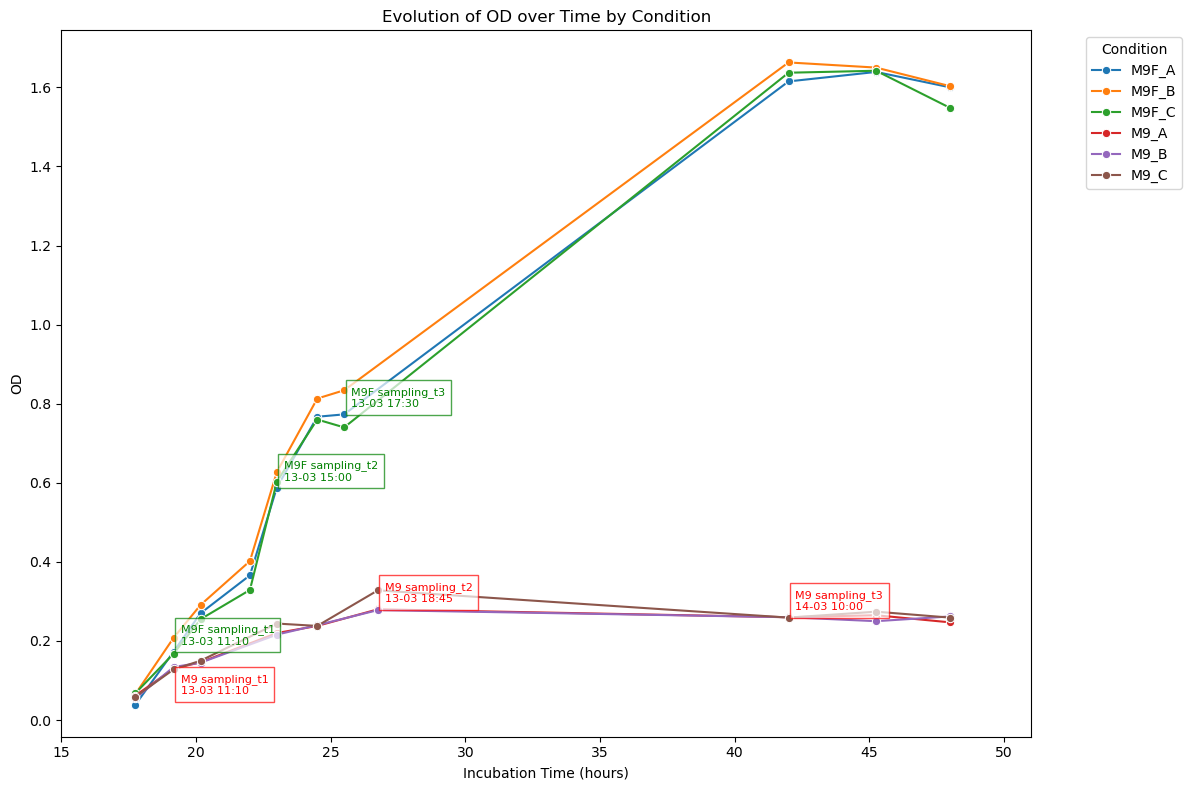

In [161]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Exemple de fonction pour convertir "XXhYY" en pd.Timedelta
def str_to_timedelta(s):
    try:
        h, m = s.split("h")
        return pd.Timedelta(hours=int(h), minutes=int(m))
    except Exception:
        return pd.NaT  # si la conversion échoue


# Appliquer la conversion à la colonne "Incubation_t"
merged_df["Incubation_timedelta"] = merged_df["Incubation_t"].apply(str_to_timedelta)

# Créer une colonne numérique en heures pour l'axe x
merged_df["Incubation_hours"] = (
    merged_df["Incubation_timedelta"].dt.total_seconds() / 3600
)

plt.figure(figsize=(12, 8))

# Tracer le graphique avec la colonne numérique et forcer l'axe x à commencer à 0
sns.lineplot(data=merged_df, x="Incubation_hours", y="OD", hue="Condition", marker="o")
plt.xlim(15, max(merged_df["Incubation_hours"]) + 3)  # Force x-axis to start at 0

# Add annotations for points with ODt values but only for M9_A and M9F_A conditions
for idx, row in merged_df[
    (~merged_df["ODt"].isna()) & (merged_df["Condition"].isin(["M9_A", "M9F_A"]))
].iterrows():
    # Set color based on condition
    label_color = "green" if row["Condition"].startswith("M9F") else "red"

    # Map OD values to sampling labels with condition prefix
    od_value = str(row["ODt"]).strip()
    condition_prefix = "M9F" if row["Condition"].startswith("M9F") else "M9"

    if od_value == "OD1":
        sampling_label = f"{condition_prefix} sampling_t1"
    elif od_value == "OD2":
        sampling_label = f"{condition_prefix} sampling_t2"
    elif od_value == "OD3":
        sampling_label = f"{condition_prefix} sampling_t3"
    else:
        sampling_label = str(row["ODt"])

    # Set annotation position
    if sampling_label == "M9 sampling_t1":
        y_pos = 0.03
        xytext = (5, 10)
    else:
        y_pos = row["OD"]
        xytext = (5, 5)

    # Format time as DD-MM HH:MM
    time_str = row["Time"].strftime("%d-%m %H:%M")
    plt.annotate(
        f"{sampling_label}\n{time_str}",
        xy=(row["Incubation_hours"], y_pos),
        xytext=xytext,
        textcoords="offset points",
        fontsize=8,
        color=label_color,
        bbox=dict(facecolor="white", edgecolor=label_color, alpha=0.7),
    )

plt.title("Evolution of OD over Time by Condition")
plt.xlabel("Incubation Time (hours)")
plt.ylabel("OD")
plt.legend(title="Condition", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

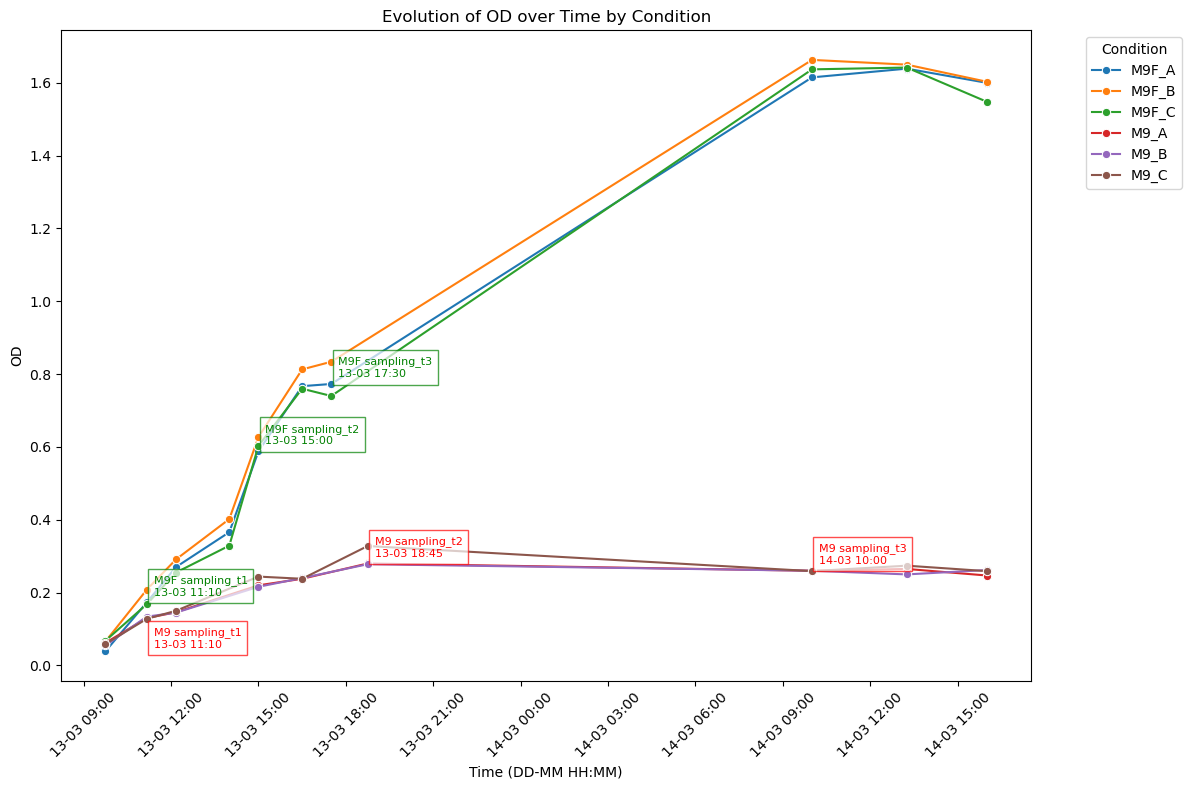

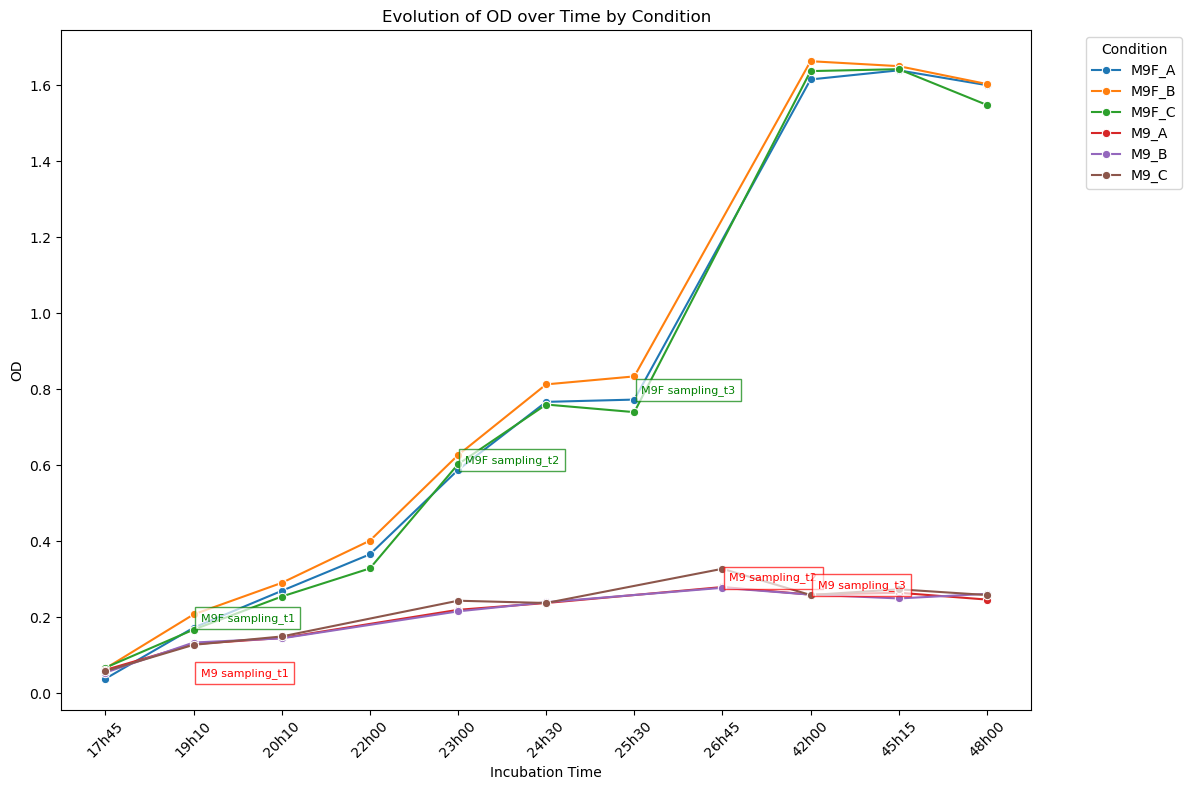

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a time series plot showing OD evolution over time for each condition
plt.figure(figsize=(12, 8))  # Adjusted figure size to be more reasonable

# Plot the main lines
sns.lineplot(data=merged_df, x="Time", y="OD", hue="Condition", marker="o")

# Add labels for points with ODt values but only for M9_A and M9F_A conditions
for idx, row in merged_df[
    (~merged_df["ODt"].isna()) & (merged_df["Condition"].isin(["M9_A", "M9F_A"]))
].iterrows():
    # Format time as DD-MM HH:MM
    time_str = row["Time"].strftime("%d-%m %H:%M")

    # Set color based on condition
    label_color = "green" if row["Condition"].startswith("M9F") else "red"

    # Map OD values to sampling labels with condition prefix
    od_value = str(row["ODt"]).strip()
    condition_prefix = "M9F" if row["Condition"].startswith("M9F") else "M9"

    if od_value == "OD1":
        sampling_label = f"{condition_prefix} sampling_t1"
    elif od_value == "OD2":
        sampling_label = f"{condition_prefix} sampling_t2"
    elif od_value == "OD3":
        sampling_label = f"{condition_prefix} sampling_t3"
    else:
        sampling_label = str(row["ODt"])

    # Set annotation position
    if sampling_label == "M9 sampling_t1":
        y_pos = 0.01  # Fixed position at 0.01
        xytext = (5, 10)  # Offset from point
    else:
        y_pos = row["OD"]
        xytext = (5, 5)

    plt.annotate(
        f"{sampling_label}\n{time_str}",
        xy=(row["Time"], y_pos),
        xytext=xytext,
        textcoords="offset points",
        fontsize=8,
        color=label_color,
        bbox=dict(facecolor="white", edgecolor=label_color, alpha=0.7),
    )

plt.title("Evolution of OD over Time by Condition")
plt.xlabel("Time (DD-MM HH:MM)")
plt.ylabel("OD")
plt.legend(title="Condition", bbox_to_anchor=(1.05, 1), loc="upper left")

# Format x-axis ticks to show date and time
plt.gca().xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d-%m %H:%M"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


import matplotlib.pyplot as plt
import seaborn as sns

# Create a time series plot showing OD evolution over time for each condition
plt.figure(figsize=(12, 8))  # Adjusted figure size to be more reasonable

# Plot the main lines
sns.lineplot(data=merged_df, x="Incubation_t", y="OD", hue="Condition", marker="o")

# Add labels for points with ODt values but only for M9_A and M9F_A conditions
for idx, row in merged_df[
    (~merged_df["ODt"].isna()) & (merged_df["Condition"].isin(["M9_A", "M9F_A"]))
].iterrows():
    # Set color based on condition
    label_color = "green" if row["Condition"].startswith("M9F") else "red"

    # Map OD values to sampling labels with condition prefix
    od_value = str(row["ODt"]).strip()
    condition_prefix = "M9F" if row["Condition"].startswith("M9F") else "M9"

    if od_value == "OD1":
        sampling_label = f"{condition_prefix} sampling_t1"
    elif od_value == "OD2":
        sampling_label = f"{condition_prefix} sampling_t2"
    elif od_value == "OD3":
        sampling_label = f"{condition_prefix} sampling_t3"
    else:
        sampling_label = str(row["ODt"])

    # Set annotation position
    if sampling_label == "M9 sampling_t1":
        y_pos = 0.01  # Fixed position at 0.01
        xytext = (5, 10)  # Offset from point
    else:
        y_pos = row["OD"]
        xytext = (5, 5)

    plt.annotate(
        f"{sampling_label}",
        xy=(row["Incubation_t"], y_pos),
        xytext=xytext,
        textcoords="offset points",
        fontsize=8,
        color=label_color,
        bbox=dict(facecolor="white", edgecolor=label_color, alpha=0.7),
    )

plt.title("Evolution of OD over Time by Condition")
plt.xlabel("Incubation Time")
plt.ylabel("OD")
plt.legend(title="Condition", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
# Install required packages if not already installed
import sys
import subprocess

def install_package(package):
    subprocess.check_call([sys.executable, "-m", "pip", "install", package])

# Install rpy2 if not already installed
try:
    import rpy2
except ImportError:
    print("Installing rpy2...")
    install_package('rpy2')

# Load R magic extension
try:
    %load_ext rpy2.ipython
    print("R magic commands enabled successfully")
except Exception as e:
    print(f"Error loading R magic: {e}")
    print("Please ensure R is installed on your system")




Installing rpy2...


/opt/anaconda3/lib/python3.12/site-packages/rpy2/rinterface/__init__.py:1211: UserWarning: Environment variable "PWD" redefined by R and overriding existing variable. Current: "/", R: "/Users/valentingoupille/Documents/Rapport_stage"
  warnings.warn(


R magic commands enabled successfully


/opt/anaconda3/lib/python3.12/site-packages/rpy2/rinterface/__init__.py:1211: UserWarning: Environment variable "R_SESSION_TMPDIR" redefined by R and overriding existing variable. Current: "/var/folders/m_/d2crsk_n0mxcl8sqs3mqkwt80000gn/T//RtmpngPnl7", R: "/var/folders/m_/d2crsk_n0mxcl8sqs3mqkwt80000gn/T//RtmpOgqzAe"
  warnings.warn(


In [ ]:
%%R
# Set working directory
library(readxl)
library(tidyverse)  # contient `%>%`, pivot_longer, etc.
library(lubridate)
setwd("/Users/valentingoupille/Documents/Rapport_stage")

# Read Excel file without column names
df <- read_excel("data/plan_exp.xlsx", col_names = FALSE)

# Check first rows
print(df)

df_long <- df %>%
  pivot_longer(-Condition, names_to = "Time", values_to = "OD") %>%
  mutate(
    Incubation_t = rep(incubation, times = nrow(df)),
    Time = dmy_hm(Time),                          # convertit en datetime
    OD = as.numeric(str_replace(OD, ",", "."))    # virgule -> point
  )

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
New names:
• `` -> `...1`
• `` -> `...2`
• `` -> `...3`
• `` -> `...4`
• `` -> `...5`
• `` -> `...6`
• `` -> `...7`
• `` -> `...8`
• `` -> `...9`
• `` -> `...10`
• `` -> `...11`
• `` -> `...12`
# A tibble: 8 × 12
  ...1         ...2  ...3  ...4  ...5  ...6  ...7  ...8  ...9     ...10    ...11
  <chr>        <chr> <chr> <chr> <chr> <chr> <chr> <chr> <chr>    <dbl>    <dbl>
1 Time         13/0… 4572… 4572… 13/0… 13/0… 13/0… 4572… 4572…  4.57e+4  4.57e+4
2 Incubation_t 17h45

RInterpreterError: Failed to parse and evaluate line '# Set working directory\nlibrary(readxl)\n\nlibrary(tidyverse)  # contient `%>%`, pivot_longer, etc.\nlibrary(lubridate)\nsetwd("/Users/valentingoupille/Documents/Rapport_stage")\n\n# Read Excel file without column names\ndf <- read_excel("data/plan_exp.xlsx", col_names = FALSE)\n\n# Check first rows\nprint(df)\n\ndf_long <- df %>%\n  pivot_longer(-Condition, names_to = "Time", values_to = "OD") %>%\n  mutate(\n    Incubation_t = rep(incubation, times = nrow(df)),\n    Time = dmy_hm(Time),                          # convertit en datetime\n    OD = as.numeric(str_replace(OD, ",", "."))    # virgule -> point\n  )\n'.
R error message: 'Error in pivot_longer(., -Condition, names_to = "Time", values_to = "OD") :'
R stdout:
Warning messages:
1: Expecting numeric in J1 / R1C10: got a date 
2: Expecting numeric in K1 / R1C11: got a date 
3: Expecting numeric in L1 / R1C12: got a date